# 07 · Frecuencia y distribución

Simulamos el lanzamiento de dos dados, construimos las frecuencias absolutas y relativas de la suma, y las comparamos con la ley teórica, su esperanza y su varianza.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)

## 1. Lanzamientos

`rng.integers(1, 7, size=(n, 2))` produce $n$ lanzamientos de dos dados (el extremo derecho se excluye).

In [2]:
def sumas_de_dos_dados(n):
    return rng.integers(1, 7, size=(n, 2)).sum(axis=1)

print("Una tirada:", sumas_de_dos_dados(1)[0])
lanzamientos = 1000
resultados = pd.Series(sumas_de_dos_dados(lanzamientos))

Una tirada: 8


## 2. Frecuencias absolutas y relativas

In [3]:
frecuencia = resultados.value_counts().reindex(range(2, 13), fill_value=0)
frecuencia.to_frame("frecuencia").T

,2,3,4,5,6,7,8,9,10,11,12
frecuencia,27,45,84,114,132,164,141,126,82,53,32


La **frecuencia relativa** divide entre el número de lanzamientos. La comparamos con la ley teórica $p_k=\frac{6-|k-7|}{36}$.

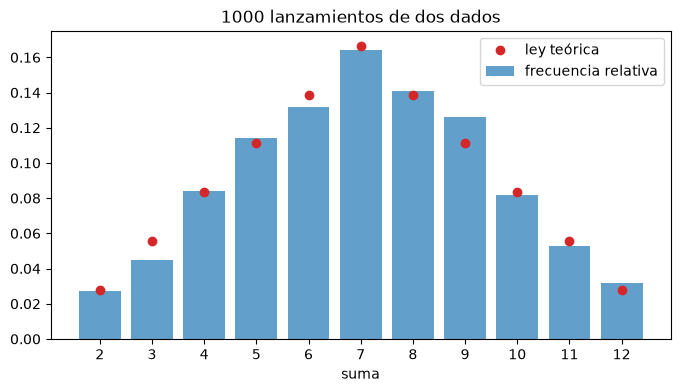

In [4]:
k = np.arange(2, 13)
ley = (6 - np.abs(k - 7)) / 36

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(k, frecuencia / lanzamientos, label="frecuencia relativa", alpha=0.7)
ax.plot(k, ley, "o", color="tab:red", label="ley teórica")
ax.set_xticks(k)
ax.set_xlabel("suma")
ax.legend()
ax.set_title(f"{lanzamientos} lanzamientos de dos dados")
plt.show()

Al aumentar el número de lanzamientos, la distancia máxima entre la frecuencia relativa y la ley disminuye, aproximadamente como $1/\sqrt n$.

In [5]:
for n in [100, 1_000, 10_000, 100_000, 1_000_000]:
    f = np.bincount(sumas_de_dos_dados(n), minlength=13)[2:] / n
    print(f"n = {n:>9,}   max |f_n - p| = {np.abs(f - ley).max():.5f}")

n =       100   max |f_n - p| = 0.04889
n =     1,000   max |f_n - p| = 0.01911
n =    10,000   max |f_n - p| = 0.01149
n =   100,000   max |f_n - p| = 0.00126
n = 1,000,000   max |f_n - p| = 0.00041


## 3. Esperanza y varianza de la ley

$$\mathbb{E}[S]=\sum_{k=2}^{12}k\,p_k=7,\qquad \operatorname{Var}(S)=\sum_{k=2}^{12}(k-7)^2p_k=\frac{35}{6}.$$

También se obtienen sin la tabla: $S=X_1+X_2$ con $X_i$ independientes, $\mathbb{E}[X_i]=\frac72$ y $\operatorname{Var}(X_i)=\frac{35}{12}$.

In [6]:
X_distri = pd.DataFrame({"Prob": ley}, index=k)
esperanza = (X_distri.index * X_distri["Prob"]).sum()
varianza = ((X_distri.index - esperanza) ** 2 * X_distri["Prob"]).sum()
print(f"E[S] = {esperanza:.4f},  Var(S) = {varianza:.4f}  (35/6 = {35/6:.4f})")

E[S] = 7.0000,  Var(S) = 5.8333  (35/6 = 5.8333)


## 4. Esperanza y varianza empíricas

La media y la varianza muestrales de muchos lanzamientos aproximan los valores teóricos.

In [7]:
muestra = pd.Series(sumas_de_dos_dados(20_000))
print(f"media muestral = {muestra.mean():.4f},  varianza muestral = {muestra.var():.4f}")

media muestral = 6.9933,  varianza muestral = 5.8601


## Ejercicios

1. Repite el análisis para la suma de tres dados y calcula $\mathbb{E}[S]$ y $\operatorname{Var}(S)$.
2. Grafica $\max_k|f_n(k)-p_k|$ contra $n$ en escala log-log y estima la pendiente.